<a href="https://colab.research.google.com/github/Martazzz/student_performance_project/blob/main/notebooks/01_cleaning_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 - Data cleaning and EDA

Student performance factors project. Phase 0 (data preparation) and phase 1 (EDA).

## Style and palette

Common style for the whole project. The `ORDER` dictionary and the `apply_order` function make every chart show the categories in a logical order (Low, Medium, High) instead of the alphabetical one.

In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
)

PALETTE_SCHOOL = {"Public": "#1f77b4", "Private": "#ff7f0e"}
PALETTE_BINARY = {"No": "#9e9e9e", "Yes": "#7b3294"}
PALETTE_LEVELS = ["#9ecae1", "#4292c6", "#084594"]
BAR_COLOR = "#1f77b4"

ORDER = {
    "Parental_Involvement": ["Low", "Medium", "High"],
    "Motivation_Level": ["Low", "Medium", "High"],
    "Family_Income": ["Low", "Medium", "High"],
    "Teacher_Quality": ["Low", "Medium", "High"],
    "Peer_Influence": ["Negative", "Neutral", "Positive"],
    "Distance_from_Home": ["Near", "Moderate", "Far"],
    "Extracurricular_Activities": ["No", "Yes"],
    "Learning_Disabilities": ["No", "Yes"],
    "School_Type": ["Public", "Private"],
    "Gender": ["Female", "Male"],
    "Hours_Studied_Bins": ["Low (Q1)", "Medium-Low (Q2)", "Medium-High (Q3)", "High (Q4)"],
    "PrevScore_Band": ["Low", "Medium", "High"],
    "Tutoring_Group": ["No tutoring", "With tutoring"],
}

def apply_order(df):
    df = df.copy()
    for col, cats in ORDER.items():
        if col in df.columns:
            df[col] = pd.Categorical(df[col], categories=cats, ordered=True)
    return df

## Reading data

From the 20 columns of the dataset, we removed 3 columns: Access_to_Resources, Internet_Access and Parental_Education_Level.

In [14]:
raw_data = pd.read_csv("StudentPerformanceFactors.csv", sep=";")

col = ["Hours_Studied", "Attendance", "Parental_Involvement", "Extracurricular_Activities",
       "Sleep_Hours", "Previous_Scores", "Motivation_Level", "Tutoring_Sessions",
       "Family_Income", "Teacher_Quality", "School_Type", "Peer_Influence",
       "Physical_Activity", "Learning_Disabilities", "Distance_from_Home", "Gender", "Exam_Score"]

data = raw_data[col].copy()

print(f"The dataset has {data.shape[0]} rows and {data.shape[1]} columns")

The dataset has 6607 rows and 17 columns


## Look at the data

We look at all the numeric columns to spot impossible values.

In [15]:
data.info()
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Extracurricular_Activities  6607 non-null   object
 4   Sleep_Hours                 6607 non-null   int64 
 5   Previous_Scores             6607 non-null   int64 
 6   Motivation_Level            6607 non-null   object
 7   Tutoring_Sessions           6607 non-null   int64 
 8   Family_Income               6607 non-null   object
 9   Teacher_Quality             6529 non-null   object
 10  School_Type                 6607 non-null   object
 11  Peer_Influence              6607 non-null   object
 12  Physical_Activity           6607 non-null   int64 
 13  Learning_Disabilities       6607 non-null   obje

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


## Cleaning data

**Missing values.** We search for null values and substitute them with the mode of the variable.

In [16]:
missing = data.isna().sum()
print("Null values per column:")
print(missing[missing > 0])

for c in ["Teacher_Quality", "Distance_from_Home"]:
    data[c] = data[c].fillna(data[c].mode()[0])

print("\nRemaining missing values in dataset:", data.isna().sum().sum())

Null values per column:
Teacher_Quality       78
Distance_from_Home    67
dtype: int64

Remaining missing values in dataset: 0


**Anomalies** The exam score must be between 0 and 100, the attendance too.
We remove the rows that violate this rule and we count how many rows are removed.

In [17]:
n_before = len(data)
data = data[data["Exam_Score"].between(0, 100) & data["Attendance"].between(0, 100)]
removed = n_before - len(data)
print(f"Removed {removed} rows")

Removed 1 rows


## Numerical representation of the categories

We assign to each category a numerical representation (used later for correlations, clustering and models):

- No:0, Yes:1
- Public:0, Private:1
- Female:0, Male:1
- Low:0, Medium:1, High:2
- Negative:0, Neutral:1, Positive:2
- Near:0, Moderate:1, Far:2

In [18]:
data["Extracurricular_Activities_num"] = data["Extracurricular_Activities"].map({"No": 0, "Yes": 1})
data["School_Type_num"] = data["School_Type"].map({"Public": 0, "Private": 1})
data["Learning_Disabilities_num"] = data["Learning_Disabilities"].map({"No": 0, "Yes": 1})
data["Gender_num"] = data["Gender"].map({"Female": 0, "Male": 1})

mapping_levels_3 = {"Low": 0, "Medium": 1, "High": 2}
mapping_peer = {"Negative": 0, "Neutral": 1, "Positive": 2}
mapping_distance = {"Near": 0, "Moderate": 1, "Far": 2}

data["Parental_Involvement_num"] = data["Parental_Involvement"].map(mapping_levels_3)
data["Motivation_Level_num"] = data["Motivation_Level"].map(mapping_levels_3)
data["Family_Income_num"] = data["Family_Income"].map(mapping_levels_3)
data["Teacher_Quality_num"] = data["Teacher_Quality"].map(mapping_levels_3)
data["Peer_Influence_num"] = data["Peer_Influence"].map(mapping_peer)
data["Distance_from_Home_num"] = data["Distance_from_Home"].map(mapping_distance)

num_cols_check = [c for c in data.columns if c.endswith("_num")]
print("NaN in the numeric codes:", data[num_cols_check].isna().sum().sum())

NaN in the numeric codes: 0


## Derived variables

- `Score_Change`: difference between the new score and the previous one.
- `Hours_Studied_Bins`: hours studied split into 4 quartiles.
- `PrevScore_Band`: previous score split into 3 bands (low, medium, high), to compare students who started from the same level.
- `Tutoring_Group`: students with or without tutoring sessions.


In [19]:
data["Score_Change"] = data["Exam_Score"] - data["Previous_Scores"]

data["Hours_Studied_Bins"] = pd.qcut(data["Hours_Studied"], q=4, labels=ORDER["Hours_Studied_Bins"])
data["PrevScore_Band"] = pd.qcut(data["Previous_Scores"], q=3, labels=ORDER["PrevScore_Band"])
data["Tutoring_Group"] = np.where(data["Tutoring_Sessions"] > 0, "With tutoring", "No tutoring")

print("Students per hours bin:")
print(data["Hours_Studied_Bins"].value_counts().reindex(ORDER["Hours_Studied_Bins"]))
print("\nReal range of each hours bin:")
print(data.groupby("Hours_Studied_Bins", observed=True)["Hours_Studied"].agg(["min", "max"]))

print("\nReal range of each previous-score band:")
print(data.groupby("PrevScore_Band", observed=True)["Previous_Scores"].agg(["min", "max", "count"]))

print("\nTutoring groups:")
print(data["Tutoring_Group"].value_counts())

Students per hours bin:
Hours_Studied_Bins
Low (Q1)            1856
Medium-Low (Q2)     1688
Medium-High (Q3)    1601
High (Q4)           1461
Name: count, dtype: int64

Real range of each hours bin:
                    min  max
Hours_Studied_Bins          
Low (Q1)              1   16
Medium-Low (Q2)      17   20
Medium-High (Q3)     21   24
High (Q4)            25   44

Real range of each previous-score band:
                min  max  count
PrevScore_Band                 
Low              50   67   2305
Medium           68   83   2110
High             84  100   2191

Tutoring groups:
Tutoring_Group
With tutoring    5093
No tutoring      1513
Name: count, dtype: int64


## Clean dataset

We apply the order of the categories and save the file. The saved CSV uses the **comma** as separator
and does not remember the order of the categories: in the other notebooks load it with
`pd.read_csv("student_performance_cleaned.csv")` and then call `data = apply_order(data)`.

In [20]:
data = apply_order(data)
print(f"Final dataset: {data.shape[0]} rows, {data.shape[1]} columns")

file_name = "student_performance_cleaned.csv"
data.to_csv(file_name, index=False)

Final dataset: 6606 rows, 31 columns


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Type of data**

---
We slipt the data into two categories: the categorical data and the numerical data

In [21]:
import os

os.makedirs("figures", exist_ok=True)

cat_cols = ["Gender", "School_Type", "Learning_Disabilities", "Extracurricular_Activities",
            "Parental_Involvement", "Motivation_Level", "Family_Income", "Teacher_Quality",
            "Peer_Influence", "Distance_from_Home"]

num_cols = ["Hours_Studied", "Attendance", "Sleep_Hours", "Previous_Scores",
            "Tutoring_Sessions", "Physical_Activity", "Exam_Score"]

# **Categorical data count**

For each categorical parameter we count the students and visualize the bar plots.

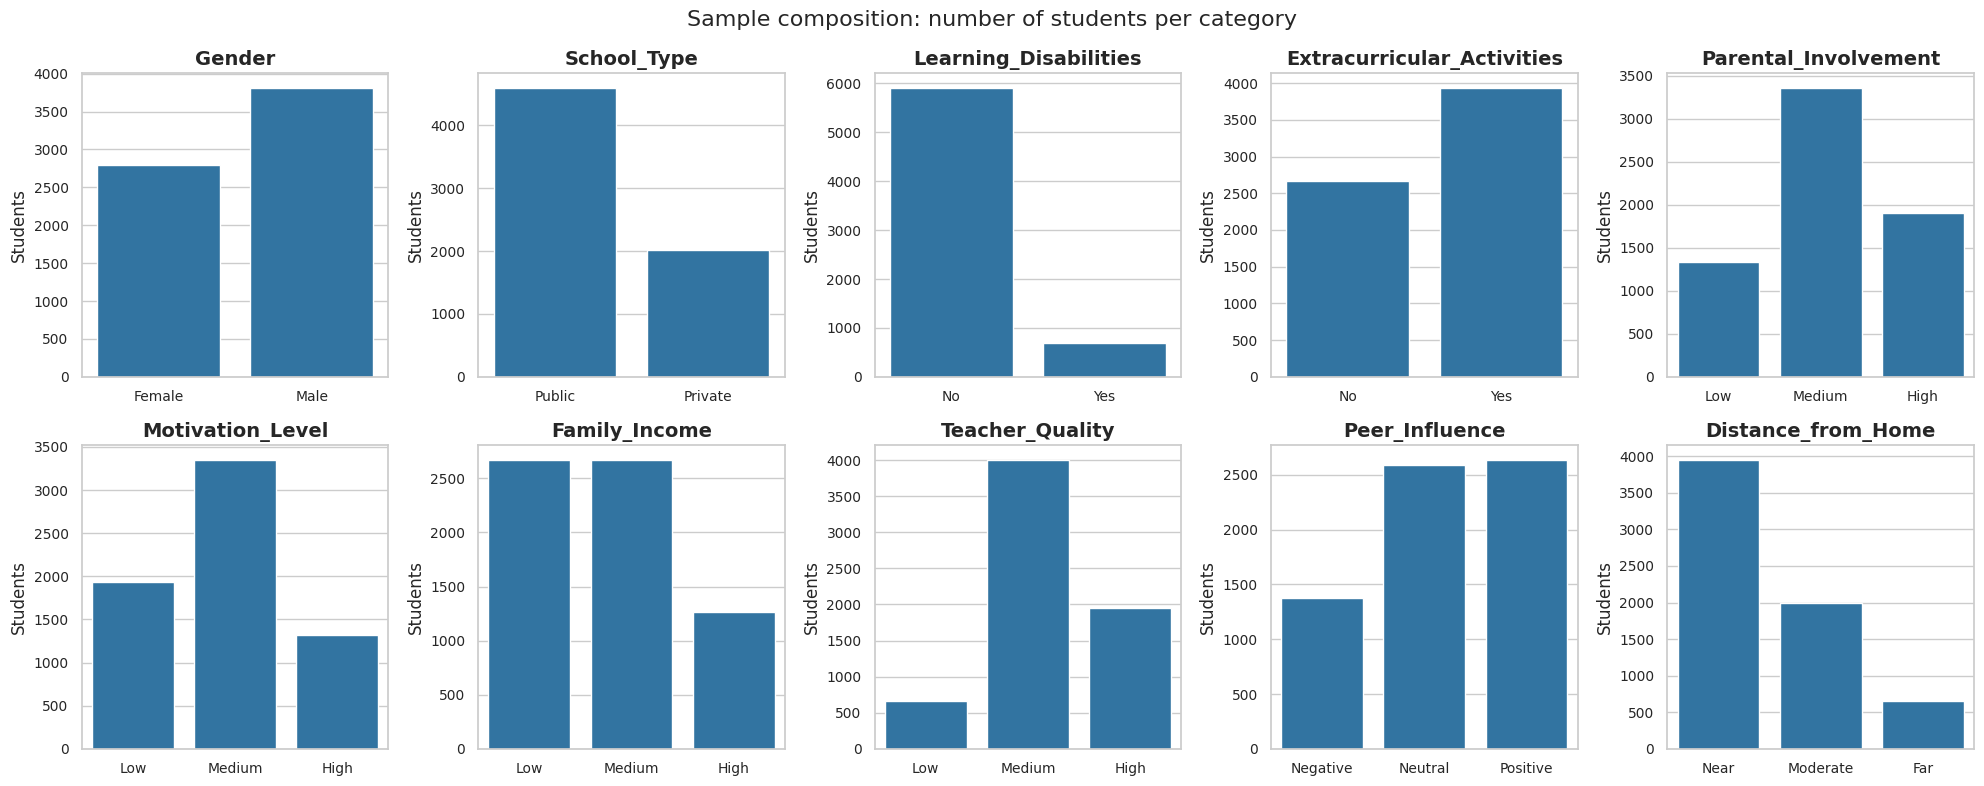

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for ax, col in zip(axes.flat, cat_cols):
    sns.countplot(data=data, x=col, color=BAR_COLOR, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Students")

fig.suptitle("Sample composition: number of students per category", fontsize=16)
plt.tight_layout()
plt.savefig("figures/eda_categorical.png", dpi=200, bbox_inches="tight")
plt.show()

# **Numerical data distribution**

For each numerical parameter we visualize the distribution of its values

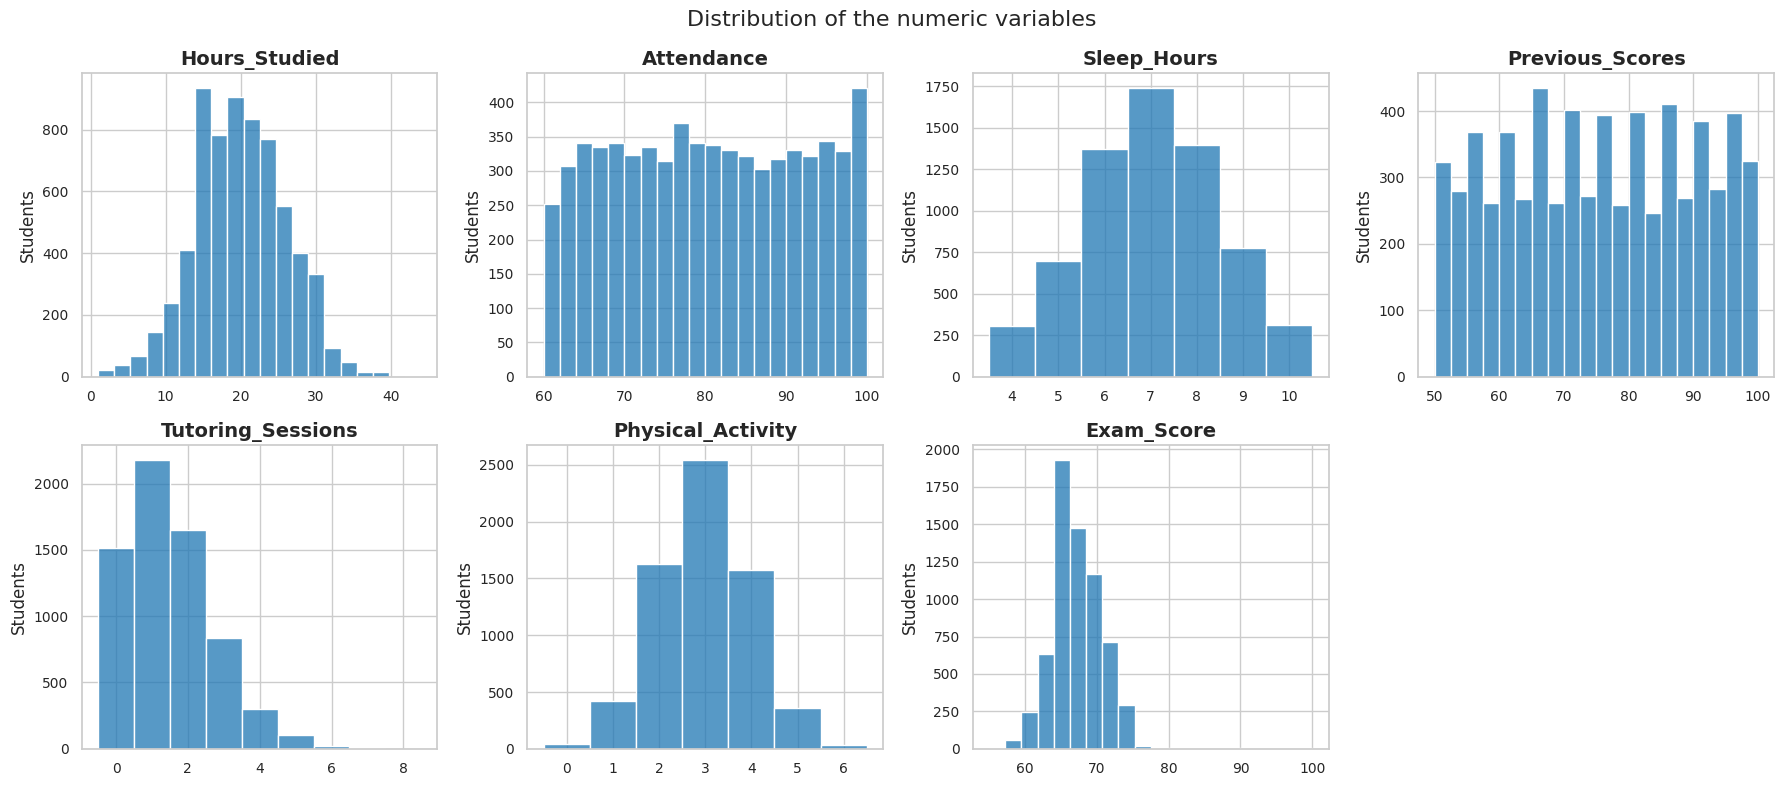

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flat, num_cols):
    if data[col].nunique() < 15:
        sns.histplot(data=data, x=col, discrete=True, color=BAR_COLOR, ax=ax)
    else:
        sns.histplot(data=data, x=col, bins=20, color=BAR_COLOR, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Students")

axes.flat[-1].axis("off")
fig.suptitle("Distribution of the numeric variables", fontsize=16)
plt.tight_layout()
plt.savefig("figures/eda_numeric.png", dpi=200, bbox_inches="tight")
plt.show()

# **Data correlation**

We consider the numerical parmeters and the numerical version of categorical parameters produced in the `Phase 0` of the project (for example Low, Medium and High became 0,1 and 2) and we see which parameters are correlated using a heatmap.



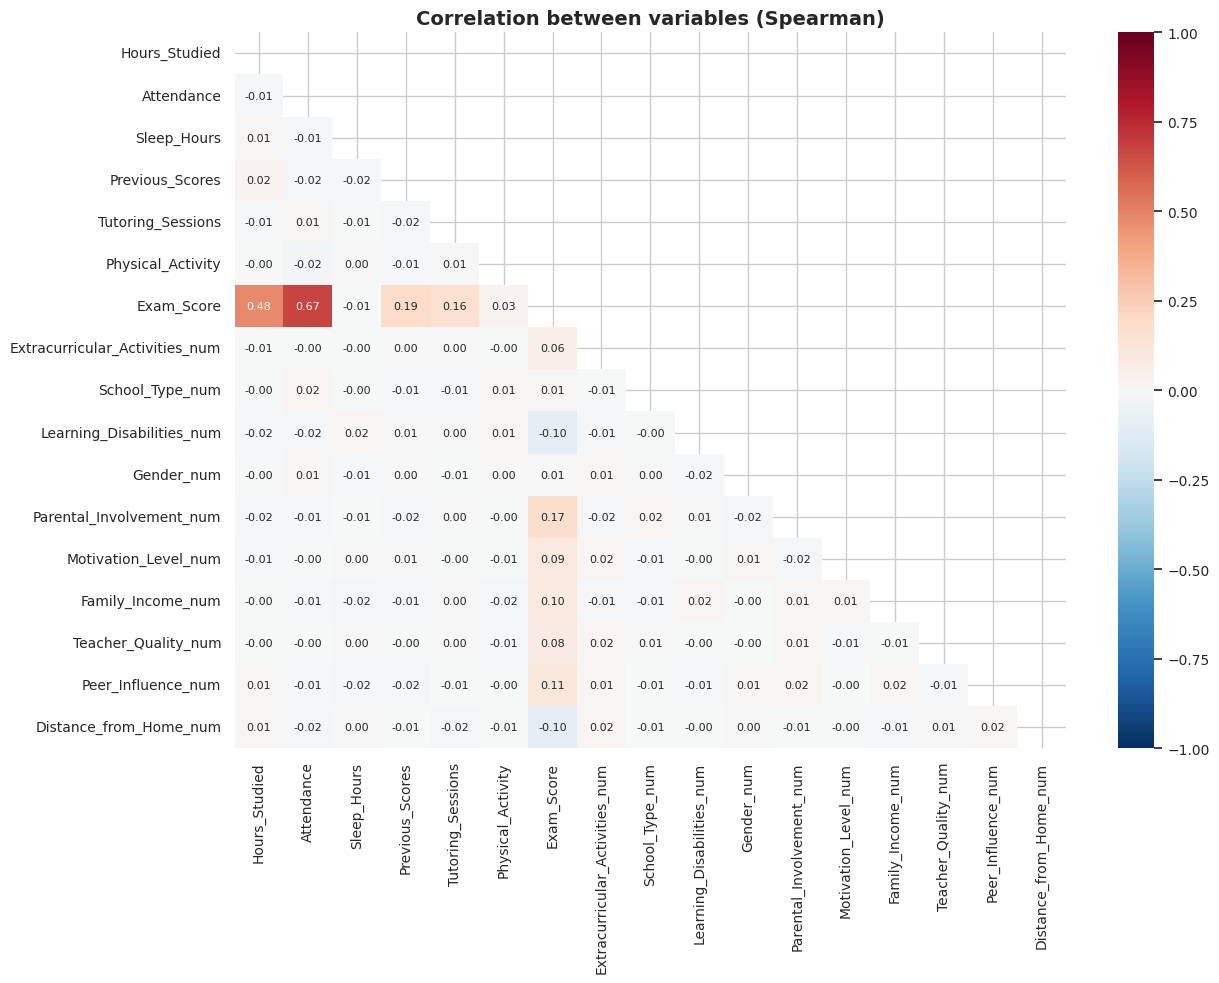

In [24]:
num_codes = [c for c in data.columns if c.endswith("_num")]
corr_cols = num_cols + num_codes
corr = data[corr_cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, annot_kws={"size": 8})
plt.title("Correlation between variables (Spearman)")
plt.tight_layout()
plt.savefig("figures/eda_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()